# 🧬 Proje 3 · Bölüm 1 — Metafaz görüntüsünden kromozom sayımına
**Seviye: Başlangıç → Orta**

Sitogenetik laboratuvarında karyotip analizi şöyle yapılır: Hücreler metafazda durdurulur, boyanır (G-bantlama), mikroskopta fotoğraflanır ve uzman **kromozomları tek tek sayar, eşleştirir ve dizer**. Bu iş hücre başına 15–30 dakika sürebilir ve deneyim ister. Görüntü işleme ve yapay zeka bu süreci hızlandırmak için yaygın biçimde araştırılıyor.

| Bölüm | Konu | Seviye |
|---|---|---|
| **3.1 (bu dosya)** | Klasik görüntü işleme: eşikleme, nesne bulma, sayım, değen kromozomları ayırma | Başlangıç-Orta |
| 3.2 | Derin öğrenme ile kromozom sınıflandırma, dijital karyogram, anöploidi tespiti | İleri |
| 3.3 | DNA dizisini görüntüye çevirme (Kaos Oyunu) ve gen ailesi sınıflandırma | Orta-İleri |

> ⚠️ **Önemli:** Bu bölümlerdeki metafaz görüntüleri **sentetik (bilgisayarda simüle edilmiş)** görüntülerdir (`karyotip_sim.py`). Gerçek kromozomların göreli uzunlukları, sentromer konumları ve kendine özgü bant desenleri modellenmiştir; ancak gerçek preparatlardaki bükülme, üst üste binme ve boyanma farklılıkları çok daha karmaşıktır. Sentetik veri, **etiketi kesin olarak bilinen** bir ortamda yöntem öğrenmek ve geliştirmek için kullanılır.

In [1]:
# Google Colab'da çalışıyorsanız proje klasörünü (zip) yükleyin
import os, sys
if "google.colab" in sys.modules and not os.path.exists("veri"):
    from google.colab import files
    print("Lütfen 03_Genetik.zip dosyasını seçin"); files.upload()
    !unzip -q -o 03_Genetik.zip
    %cd 03_Genetik
print("Çalışma klasörü:", os.getcwd())

Çalışma klasörü: /home/claude/SaglikYZ/03_Genetik


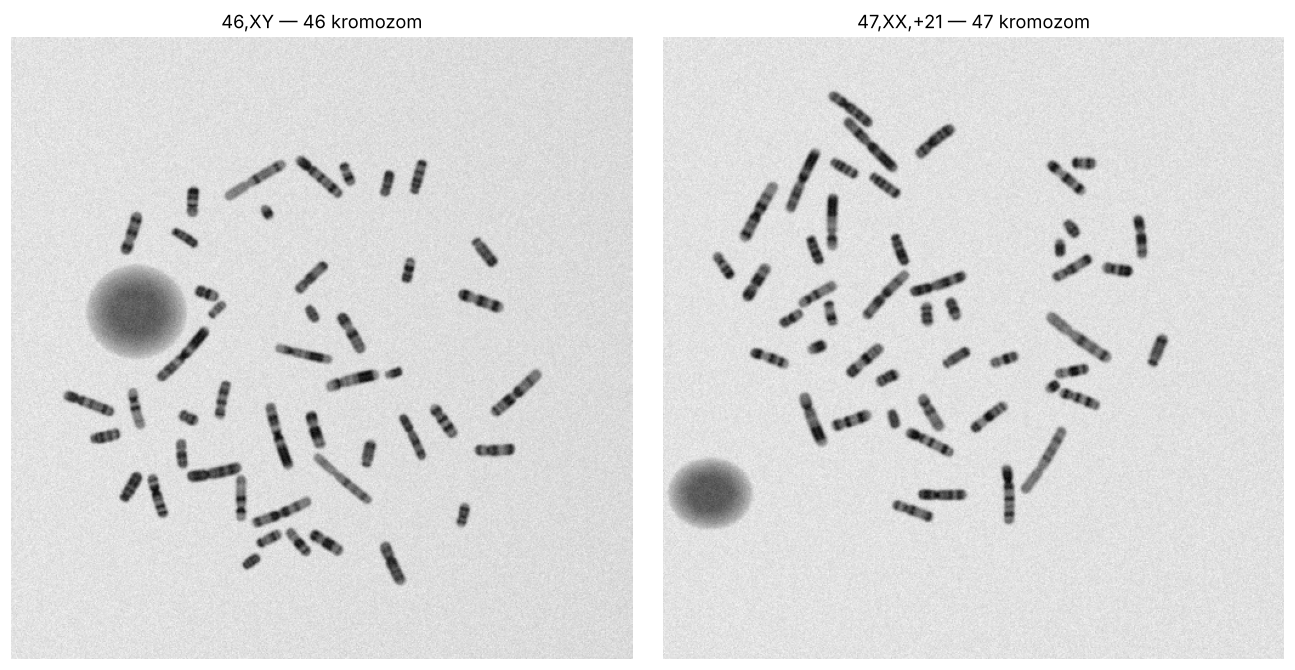

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, os
from PIL import Image
from karyotip_sim import metafaz_uret, KARYOTIPLER, TIPLER
from kromozom_isleme import bulaniklastir, otsu, nesneleri_bul
plt.rcParams["figure.dpi"] = 110

normal, _, kayit_n = metafaz_uret("46,XY", tohum=11, cekirdek=1)
down, _, kayit_d = metafaz_uret("47,XX,+21 (Down)", tohum=12, cekirdek=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(normal, cmap="gray"); ax[0].set_title(f"46,XY — {len(kayit_n)} kromozom")
ax[1].imshow(down, cmap="gray"); ax[1].set_title(f"47,XX,+21 — {len(kayit_d)} kromozom")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

Bir insan gözüyle bakınca ilk soru: **Kaç kromozom var?** 46 mı, 47 mi, 45 mi? Bu tek bir sayı bile **sayısal kromozom anomalilerini** (Down, Edwards, Patau, Turner, Klinefelter) düşündürmeye yeter.

## 1. Adım: Kromozomları arka plandan ayırmak (eşikleme)
Kromozomlar koyu, arka plan açık. Parlaklık histogramında iki tepe görürüz. **Otsu yöntemi**, iki grubu en iyi ayıran eşiği otomatik bulur (her görüntü için ayrı ayrı).

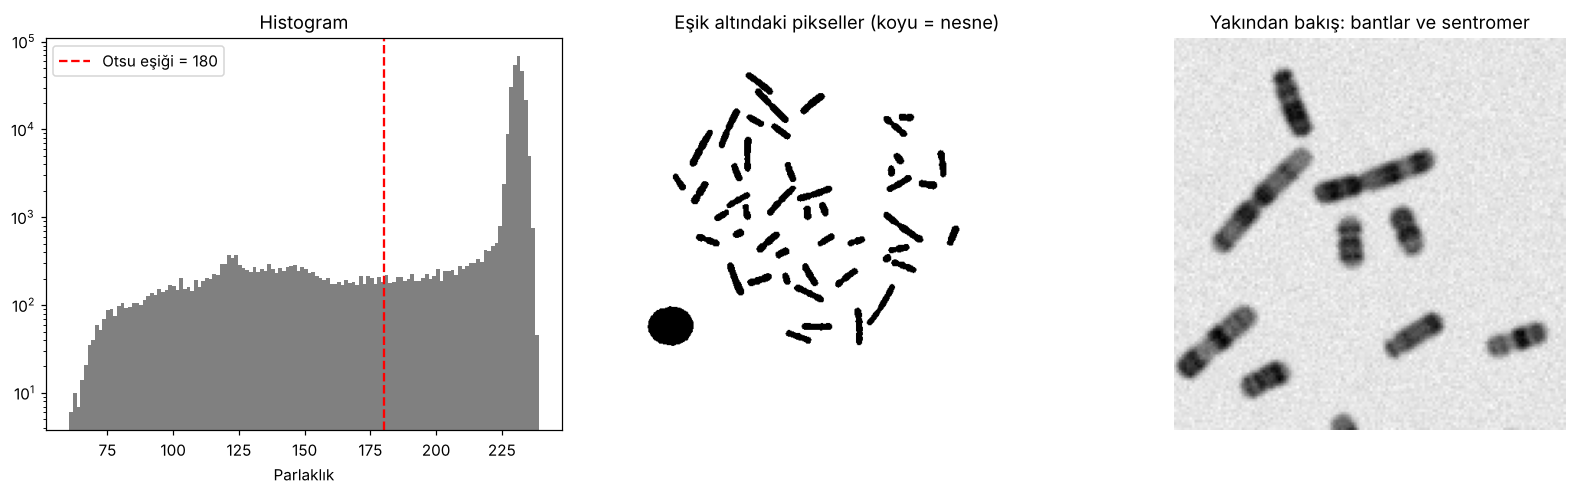

In [3]:
b = bulaniklastir(down.astype(float))
t = otsu(b)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].hist(b.ravel(), bins=128, color="gray"); ax[0].axvline(t, c="red", ls="--", label=f"Otsu eşiği = {t}")
ax[0].set_yscale("log"); ax[0].set_xlabel("Parlaklık"); ax[0].legend(); ax[0].set_title("Histogram")
ax[1].imshow(b <= t, cmap="gray_r"); ax[1].set_title("Eşik altındaki pikseller (koyu = nesne)")
ax[2].imshow(down[150:300, 150:300], cmap="gray"); ax[2].set_title("Yakından bakış: bantlar ve sentromer")
for a in ax[1:]: a.axis("off")
plt.tight_layout(); plt.show()

## 2. Adım: Her bir nesneyi bulmak (bağlı bileşen analizi)
Birbirine değen koyu pikseller tek bir **nesne** sayılır. Her nesne için **alan** ve **uzama** (uzunluk/genişlik oranı) hesaplarız:
* çok küçük → gürültü / kir
* büyük ve yuvarlak → **ara faz çekirdeği** (sayıma katılmaz)
* çok büyük ve düzensiz → **kümelenme** (değen/üst üste binen kromozomlar)
* geri kalanlar → **tek kromozom**

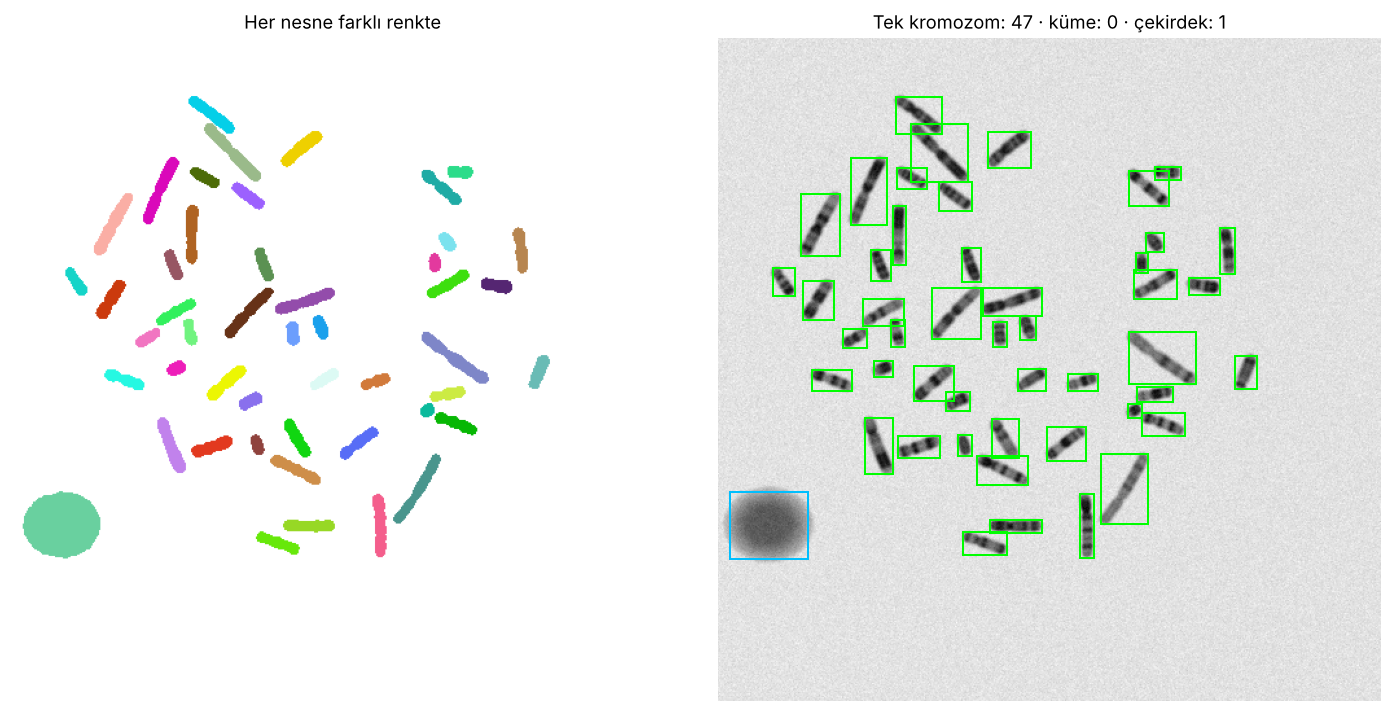

,alan,uzama
count,48.0,48.0
mean,321.2,3.7
std,323.2,1.6
min,96.0,1.2
25%,189.8,2.5
50%,275.5,3.5
75%,354.5,4.6
max,2380.0,7.6


In [4]:
etiket, nesneler, esik = nesneleri_bul(down)
renk = {"kromozom": "lime", "kume": "orange", "cekirdek": "deepskyblue"}
fig, ax = plt.subplots(1, 2, figsize=(13, 6.4))
rastgele = np.random.default_rng(0).random((etiket.max() + 1, 3)); rastgele[0] = 1
ax[0].imshow(rastgele[etiket]); ax[0].set_title("Her nesne farklı renkte"); ax[0].axis("off")
ax[1].imshow(down, cmap="gray"); ax[1].axis("off")
for n in nesneler:
    y0, x0, y1, x1 = n["bbox"]
    ax[1].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=renk[n["tur"]], lw=1.3))
sayim = pd.Series([n["tur"] for n in nesneler]).value_counts()
ax[1].set_title(f"Tek kromozom: {sayim.get('kromozom', 0)} · küme: {sayim.get('kume', 0)} · çekirdek: {sayim.get('cekirdek', 0)}")
plt.tight_layout(); plt.show()
pd.DataFrame(nesneler)[["alan", "uzama", "tur"]].describe().round(1)

## 3. Veri seti: 160 metafaz görüntüsü
Yöntemi tek bir görüntüde değil, **çok sayıda görüntüde** sınamalıyız. 8 karyotip × 20 hücre üretiyoruz; her görüntüde kromozomların birbirine **değme olasılığı** farklı (kolay → zor). Her görüntünün doğru cevabı (karyotip, kromozom sayısı, her kromozomun tipi ve yeri) `veri/metafaz/etiketler.json` dosyasında.

In [5]:
os.makedirs("veri/metafaz", exist_ok=True)
etiketler = []
zorluklar = {"kolay": 0.0, "orta": 0.04, "zor": 0.25}
for i in range(160):
    kt = list(KARYOTIPLER)[i % 8]
    zorluk = ["kolay", "kolay", "orta", "zor"][(i // 8) % 4]
    g, et, kayit = metafaz_uret(kt, temas_orani=zorluklar[zorluk], cekirdek=i % 3, tohum=5000 + i)
    ad = f"metafaz_{i:03d}.png"
    Image.fromarray(g).save(f"veri/metafaz/{ad}", optimize=True)
    etiketler.append({"dosya": ad, "karyotip": kt, "kromozom_sayisi": len(kayit), "zorluk": zorluk, "kromozomlar": kayit})
json.dump(etiketler, open("veri/metafaz/etiketler.json", "w"), ensure_ascii=False)
veri = pd.DataFrame(etiketler)[["dosya", "karyotip", "kromozom_sayisi", "zorluk"]]
print(veri.groupby(["karyotip"]).size().to_string())
print("Toplam boyut: %.1f MB" % (sum(os.path.getsize("veri/metafaz/" + f) for f in os.listdir("veri/metafaz")) / 1e6))

karyotip
45,X (Turner)           20
46,XX                   20
46,XY                   20
47,XX,+18 (Edwards)     20
47,XX,+21 (Down)        20
47,XXY (Klinefelter)    20
47,XY,+13 (Patau)       20
47,XY,+21 (Down)        20
Toplam boyut: 27.9 MB


## 4. Otomatik sayım ne kadar doğru?

In [6]:
sonuc = []
for e in etiketler:
    g = np.asarray(Image.open("veri/metafaz/" + e["dosya"]).convert("L"))
    _, ns, _ = nesneleri_bul(g)
    tek = sum(n["tur"] == "kromozom" for n in ns); kume = sum(n["tur"] == "kume" for n in ns)
    sonuc.append({"zorluk": e["zorluk"], "gercek": e["kromozom_sayisi"], "bulunan": tek, "kume": kume})
s = pd.DataFrame(sonuc)
s["dogru_sayim"] = (s.gercek == s.bulunan) & (s.kume == 0)
s["fark"] = s.bulunan - s.gercek
ozet = s.groupby("zorluk").agg(hucre=("gercek", "size"), dogru_sayim_orani=("dogru_sayim", "mean"),
                                ort_eksik=("fark", lambda f: -f.mean()), kume_iceren=("kume", lambda k: (k > 0).mean()))
ozet.loc[["kolay", "orta", "zor"]].round(2)

,hucre,dogru_sayim_orani,ort_eksik,kume_iceren
zorluk,,,,
kolay,80,0.94,0.06,0.00
orta,40,0.45,1.05,0.08
zor,40,0.00,6.12,0.45


**Gözlem:** Kromozomlar ayrık olduğunda basit yöntem neredeyse kusursuz; ama birbirine **değen** kromozomlar tek bir nesne gibi görünür ve sayım düşer. Gerçek preparatlarda en büyük sorun budur ve hâlâ aktif bir **araştırma** konusudur (*overlapping chromosome segmentation*).

## 5. İleri adım: Değen kromozomları ayırmak (mesafe dönüşümü + havza / *watershed*)
Fikir: Her pikselin arka plana uzaklığını hesaplarız. Bir kromozomun "omurgası" yüksek değerli bir sırttır; iki kromozom değdiğinde **iki ayrı tepe** oluşur. Havza algoritması, suyun bu tepelerden aşağı akışını taklit ederek nesneyi böler.

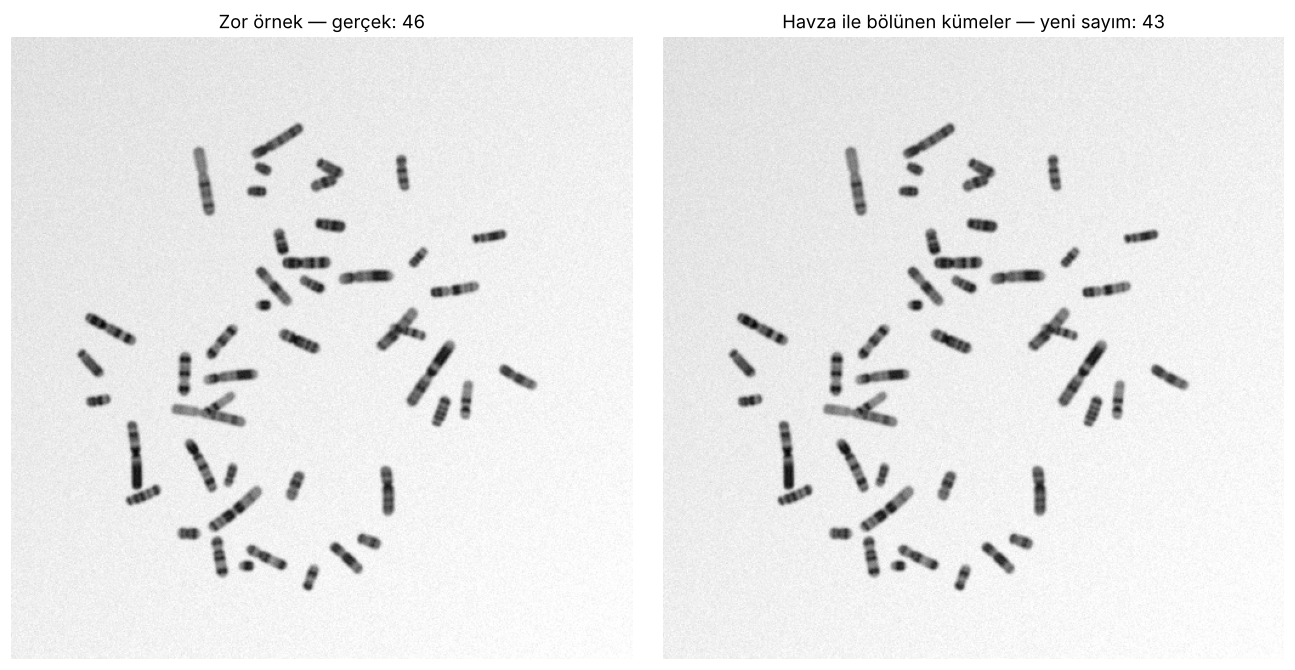

In [7]:
from scipy import ndimage
from skimage.segmentation import watershed
from skimage.feature import peak_local_max

def havza_ile_say(g):
    b = bulaniklastir(g.astype(float)); maske = b <= otsu(b)
    et, ns, _ = nesneleri_bul(g)
    tek = sum(n["tur"] == "kromozom" for n in ns); ek = 0; bolunmus = np.zeros_like(et)
    for n in ns:
        if n["tur"] != "kume":
            continue
        m = et == n["no"]
        mesafe = ndimage.distance_transform_edt(m)
        tepeler = peak_local_max(mesafe, min_distance=7, threshold_abs=2.5, labels=m.astype(int), exclude_border=False)
        isaret = np.zeros_like(et); isaret[tuple(tepeler.T)] = np.arange(1, len(tepeler) + 1)
        parcalar = watershed(-mesafe, isaret, mask=m)
        ek += max(1, len(np.unique(parcalar)) - 1)
        bolunmus[m] = parcalar[m] + bolunmus.max()
    return tek + ek, bolunmus

ornek = next(e for e in etiketler if e["zorluk"] == "zor")
g = np.asarray(Image.open("veri/metafaz/" + ornek["dosya"]).convert("L"))
toplam, bolunmus = havza_ile_say(g)
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(g, cmap="gray"); ax[0].set_title(f"Zor örnek — gerçek: {ornek['kromozom_sayisi']}")
ax[1].imshow(g, cmap="gray"); ax[1].imshow(np.ma.masked_equal(bolunmus, 0), cmap="tab20", alpha=.7)
ax[1].set_title(f"Havza ile bölünen kümeler — yeni sayım: {toplam}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

In [8]:
s["havza"] = [havza_ile_say(np.asarray(Image.open("veri/metafaz/" + e["dosya"]).convert("L")))[0] for e in etiketler]
s["havza_dogru"] = s.havza == s.gercek
s["mutlak_hata_basit"] = (s.bulunan + s.kume - s.gercek).abs()     # her kümeyi 1 sayarsak
s["mutlak_hata_havza"] = (s.havza - s.gercek).abs()
s.groupby("zorluk")[["dogru_sayim", "havza_dogru", "mutlak_hata_basit", "mutlak_hata_havza"]].mean().loc[["kolay", "orta", "zor"]].round(2)

,dogru_sayim,havza_dogru,mutlak_hata_basit,mutlak_hata_havza
zorluk,,,,
kolay,0.94,0.94,0.06,0.06
orta,0.45,0.45,0.98,1.00
zor,0.00,0.08,5.35,4.05


## ✅ Çıkarımlar
* **Eşikleme + bağlı bileşen analizi** gibi basit görüntü işleme yöntemleri, iyi yayılmış metafazlarda sayımı otomatikleştirebilir.
* Değen/üst üste binen kromozomlar asıl zorluktur; **havza** gibi klasik yöntemler kısmen çözer, günümüzde derin öğrenme tabanlı **örnek segmentasyonu** (instance segmentation) kullanılır.
* Sayı tek başına anöploidiyi düşündürür ama **hangi** kromozomun fazla olduğunu söylemez → Bölüm 3.2.

💡 **Araştırma fikirleri**
1. Laboratuvarınızın gerçek metafaz görüntülerinde bu basit yöntemin **sayım doğruluğu** ve uzmanla uyumu (Bland-Altman).
2. Hangi preparat özellikleri (yayılım kalitesi, bant çözünürlüğü) otomatik analizi zorlaştırıyor? → **kalite skoru** geliştirme.
3. **Sentetik veriyle ön eğitim + az sayıda gerçek görüntüyle ince ayar**: gerçek veri ihtiyacını ne kadar azaltır?